Ансамбли
(бэггинг, стекинг, бустинг)

Бэггинг

Каждая модель обучается на boot_strap выборки параллельно(независимо друг от друга), после получения результатов, они оцениваются на общем голосовании

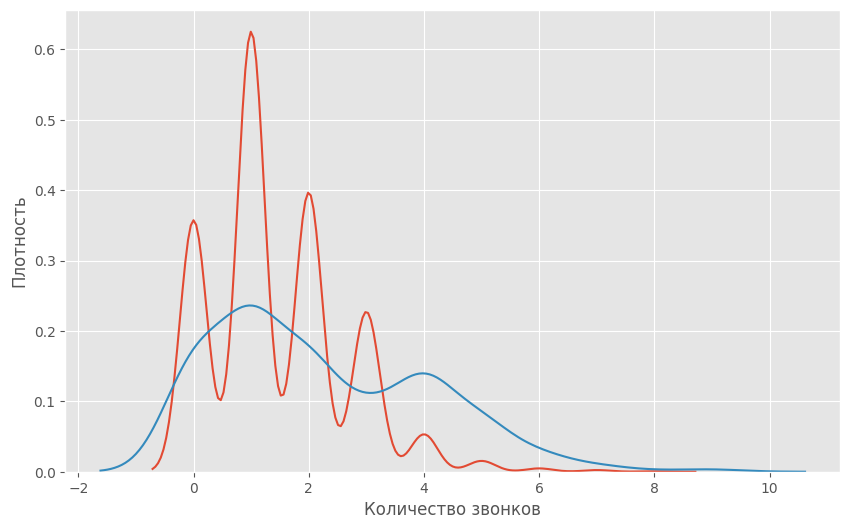

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
plt.style.use('ggplot')
plt.rcParams['figure.figsize'] = 10, 6
import seaborn as sns
# %matplotlib inline


URL = 'https://drive.google.com/uc?id=1U9LC5ECI2_Jvq4FrZNCOn3gCT7T5Y5DD'
telecom_date = pd.read_csv(URL)

fig = sns.kdeplot(telecom_date[telecom_date['Churn'] == False]['Customer service calls'], label='Loyal')
fig = sns.kdeplot(telecom_date[telecom_date['Churn'] == True]['Customer service calls'], label='Churn')

fig.set(xlabel='Количество звонков', ylabel='Плотность')
plt.show()

In [2]:
import numpy as np


def get_bootstrap_samples(data, n_samples, n_data):
    indices = np.random.randint(0, len(data), (n_samples, n_data))
    samples = data[indices]
    return samples

def stat_intermals(stat, alpha):
    boundaries = np.percentile(stat, [100 * alpha / 2., 100 * (1 - alpha / 2.)])
    return boundaries


n_samples = 1000
n_data = 500

loyal_calls = telecom_date[telecom_date['Churn'] == False]['Customer service calls'].values
churn_calls = telecom_date[telecom_date['Churn'] == True]['Customer service calls'].values

# 15 minuts
np.random.seed(0)

loyal_mean_scores = [np.mean(sample) for sample in get_bootstrap_samples(loyal_calls, n_samples, n_data)]
churn_mean_scores = [np.mean(sample) for sample in get_bootstrap_samples(churn_calls, n_samples, n_data)]

print('Service calls from loyal: mean interval', stat_intermals(loyal_mean_scores, .05))
print('Service calls from churn: mean interval', stat_intermals(churn_mean_scores, .05))

print('Service calls from loyal: mean', np.mean(loyal_calls))
print('Service calls from loyal: mean', np.mean(churn_calls))

Service calls from loyal: mean interval [1.35  1.556]
Service calls from churn: mean interval [2.06   2.3961]
Service calls from loyal: mean 1.4498245614035088
Service calls from loyal: mean 2.229813664596273


Бэггинг используется для уменьшения дисперсии.

Модели урвановешивают друг друга по ошибке. Причём должны быть не зависимы.

In [3]:
from sklearn.ensemble import BaggingRegressor
from sklearn.tree import DecisionTreeRegressor


n_repeat = 50
n_train = 50
n_test = 1000
noise = .1 #Дисперсия шума

np.random.seed(0)

# модели с которыми будем работать
estimators = [('Tree', DecisionTreeRegressor()),
              ('Bagging(Tree)', BaggingRegressor(DecisionTreeRegressor(), n_estimators=10, max_samples=1.))]

n_estimators = len(estimators)


In [4]:
np.random.seed(0)
def f(x):
    x = x.ravel()
    return np.exp(-x ** 2) + 1.5 * np.exp(-(x - 2) ** 2)

def generate(n_samples, noise, n_repeat=1):
    X = np.random.rand(n_samples) * 10 - 5
    X = np.sort(X)

    if n_repeat == 1:
        y = f(X) + np.random.normal(0.0, noise, n_samples)
    else:
        y = np.zeros((n_samples, n_repeat))
        for i in range(n_repeat):
            y[:, i] = f(X) + np.random.normal(0.0, noise, n_samples)

    X = X.reshape((n_samples, 1))

    return X, y

Tree         : 0.0255 (error) = 0.0003 (bias^2) + 0.0152 (var) + 0.0098 (noise)
Bagging(Tree): 0.0196 (error) = 0.0004 (bias^2) + 0.0092 (var) + 0.0098 (noise)


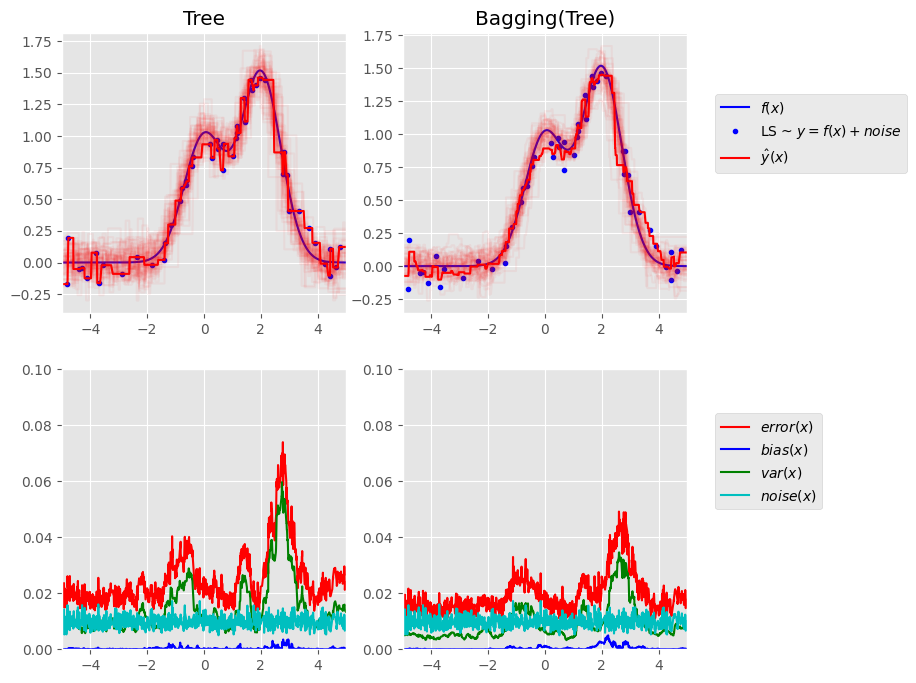

In [5]:
X_train, y_train = [], []

for i in range(n_repeat):
    X, y = generate(n_samples=n_train, noise=noise)
    X_train.append(X)
    y_train.append(y)

X_test, y_test = generate(n_samples=n_test, noise=noise, n_repeat=n_repeat)

plt.figure(figsize=(10, 8))

for n, (name, estimator) in enumerate(estimators):
    y_predict = np.zeros((n_test, n_repeat))

    for i in range(n_repeat):
        estimator.fit(X_train[i], y_train[i])
        y_predict[:, i] = estimator.predict(X_test)

    y_error = np.zeros(n_test)

    for i in range(n_repeat):
        for j in range(n_repeat):
            y_error += (y_test[:, j] - y_predict[:, i]) ** 2
    
    y_error /= (n_repeat * n_repeat)

    y_noise = np.var(y_test, axis=1)

    y_bias = (f(X_test) - np.mean(y_predict, axis=1)) ** 2
    y_var = np.var(y_predict, axis=1)

    print('{0:13.15}: {1:.4f} (error) = {2:.4f} (bias^2)'
          ' + {3:.4f} (var) + {4:.4f} (noise)'.format(name, np.mean(y_error), 
          np.mean(y_bias), np.mean(y_var), np.mean(y_noise)))
    
    plt.subplot(2, n_estimators, n + 1)
    plt.plot(X_test, f(X_test), 'b', label='$f(x)$')
    plt.plot(X_train[0], y_train[0], '.b', label='LS ~ $y = f(x) + noise$')
    
    for i in range(n_repeat):
        if i == 0:
            plt.plot(X_test, y_predict[:, i], 'r', label='$\^y(x)$')
        else:
            plt.plot(X_test, y_predict[:, i], 'r',  alpha=.05)

    plt.xlim([-5, 5])
    plt.title(name)

    if n == n_estimators - 1:
        plt.legend(loc=(1.1, .5))

    plt.subplot(2, n_estimators, n_estimators + n + 1)
    plt.plot(X_test, y_error, 'r', label='$error(x)$')
    plt.plot(X_test, y_bias, 'b', label='$bias(x)$')
    plt.plot(X_test, y_var, 'g', label='$var(x)$')
    plt.plot(X_test, y_noise, 'c', label='$noise(x)$')

    plt.xlim([-5, 5])
    plt.ylim([0, .1])

    if n == n_estimators - 1:
        plt.legend(loc=(1.1, .5))

plt.subplots_adjust(right=.75)
plt.show()
        

Разделяющая поверхность

In [6]:
from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split


def Div_plate(clf, flip_level):
    X, y = make_classification(n_samples=10000, 
                               n_features=2,
                               n_informative=2, 
                               n_redundant=0,
                               n_repeated=0,
                               n_classes=2,
                               n_clusters_per_class=1,
                               class_sep=2, 
                               flip_y=flip_level, 
                               weights=[.5, .5],
                               random_state=17)

    # n_features - кол-во признаков
    # n_informative - кол-во значимых признаков, 
    # n_redundant - кол-во незначимых прихнаков,
    # n_repeated - кол-во повторений,
    # n_classes - кол-во классов,
    # n_clusters_per_class - кол-во кластеров на класс,
    # class_sep=2 - расстояние между кластерами, 
    # flip_y=flip_level - доля ошибок, 
    # weights=[.5, .5] - балансировка выборки (% классов)

    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=.33, random_state=42)

    plt.subplots()
    ax1 = plt.gca()
    sns.scatterplot(x=X_train[:, 0], y=X_train[:, 1], hue=y_train, ax=ax1)
    sns.scatterplot(x=X_test[:, 0], y=X_test[:, 1], hue=y_test, ax=ax1)
    ax1.set_title('Data With Noise')

    clf.fit(X_train, y_train)
    y_pred = clf.predict(X_test)
    score = clf.score(X_test, y_test)
    print('Score=', score)

    ind = y_test == y_pred

    plt.subplots()
    ax2 = plt.gca()

    sns.scatterplot(x=X_test[ind, 0], y=X_test[ind, 1], hue=y_test[ind], ax=ax2)
    sns.scatterplot(x=X_test[~ind, 0], y=X_test[~ind, 1], hue=y_test[~ind], ax=ax2, marker='+')

    ax2.set_title('With Noise')

    plot_step = .01
    x_min, x_max = X[:, 0].min() - 1, X[:, 0].max() + 1
    y_min, y_max = X[:, 1].min() - 1, X[:, 1].max() + 1

# Griiidddd
    xx, yy = np.meshgrid(np.arange(x_min, x_max, plot_step), 
                         np.arange(y_min,y_max, plot_step))
    
    y_pred = clf.predict(np.c_[xx.ravel(), yy.ravel()])
    y_pred = y_pred.reshape(xx.shape)

    cs = plt.contourf(xx, yy, y_pred, levels=1, colors=['blue', 'orange'], alpha=.3)
    plt.show()

Score= 0.883030303030303


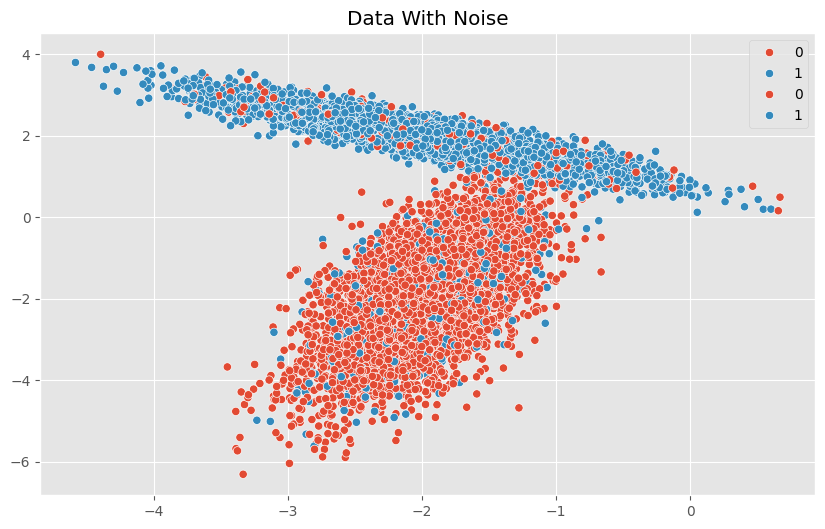

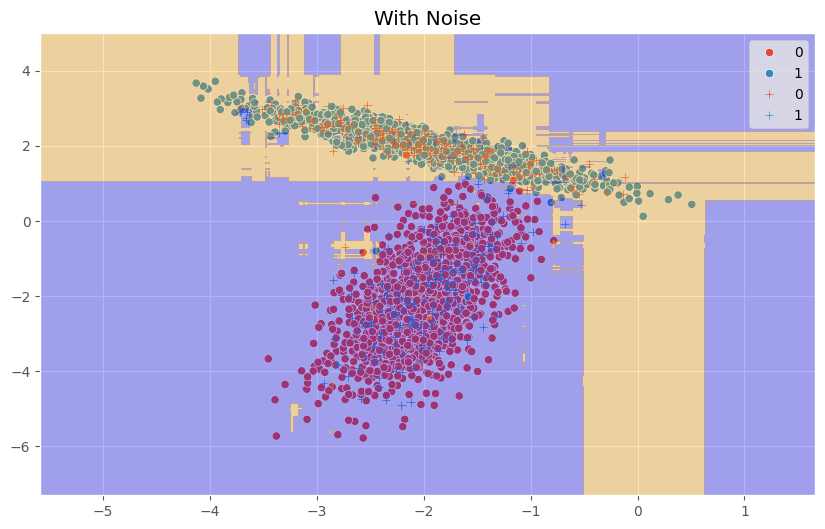

In [7]:
from sklearn.ensemble import BaggingClassifier
from sklearn.tree import DecisionTreeClassifier


clf = BaggingClassifier(DecisionTreeClassifier(), n_estimators=10, max_samples=.5)
flip_level = .2

Div_plate(clf, flip_level)

Score= 0.8824242424242424


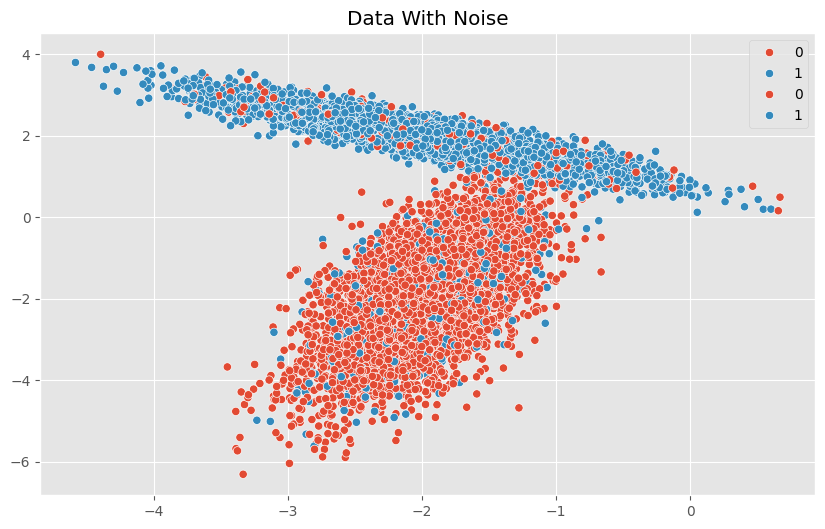

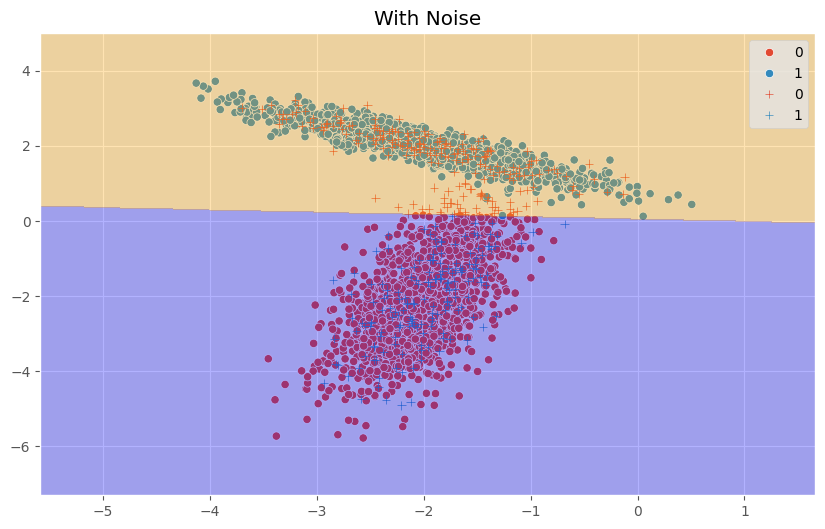

In [8]:
from sklearn.ensemble import BaggingClassifier
from sklearn.linear_model import LogisticRegression


clf = BaggingClassifier(LogisticRegression(), n_estimators=10, max_samples=.5)
flip_level = .2

Div_plate(clf, flip_level)

In [9]:
clf.estimators_[0]

,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add a L2 penalty term and it is the default choice;- `'l1'`: add a L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'` and `l1_ratio` set to any float between 0 and 1 for `'penalty='elasticnet'`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation `) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary ` for details.",941628845
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default solver because it works reasonably well for a wide class of problems.- For :term

Случайный лес

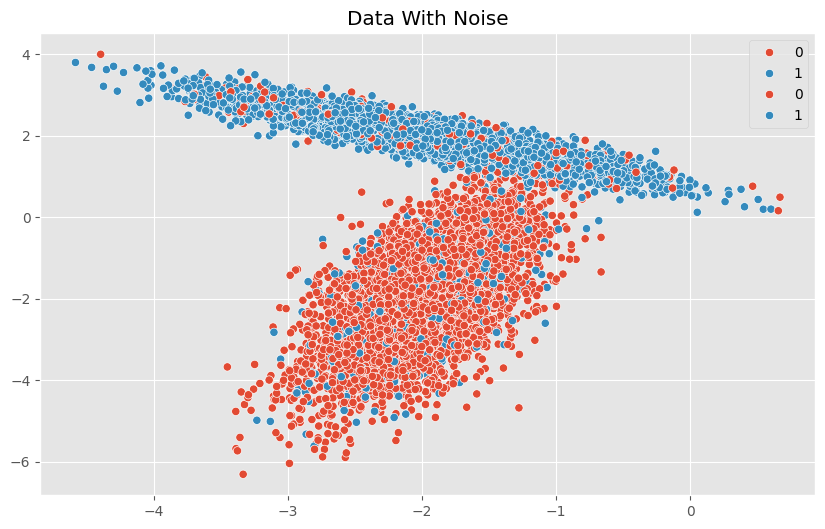

In [10]:
from sklearn.ensemble import RandomForestClassifier

X, y = make_classification(n_samples=10000, 
                               n_features=2,
                               n_informative=2, 
                               n_redundant=0,
                               n_repeated=0,
                               n_classes=2,
                               n_clusters_per_class=1,
                               class_sep=2, 
                               flip_y=flip_level, 
                               weights=[.5, .5],
                               random_state=17)


X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=.33, random_state=42)

plt.subplots()
ax1 = plt.gca()
sns.scatterplot(x=X_train[:, 0], y=X_train[:, 1], hue=y_train, ax=ax1)
sns.scatterplot(x=X_test[:, 0], y=X_test[:, 1], hue=y_test, ax=ax1)
ax1.set_title('Data With Noise')
plt.show()

Score= 0.8951515151515151


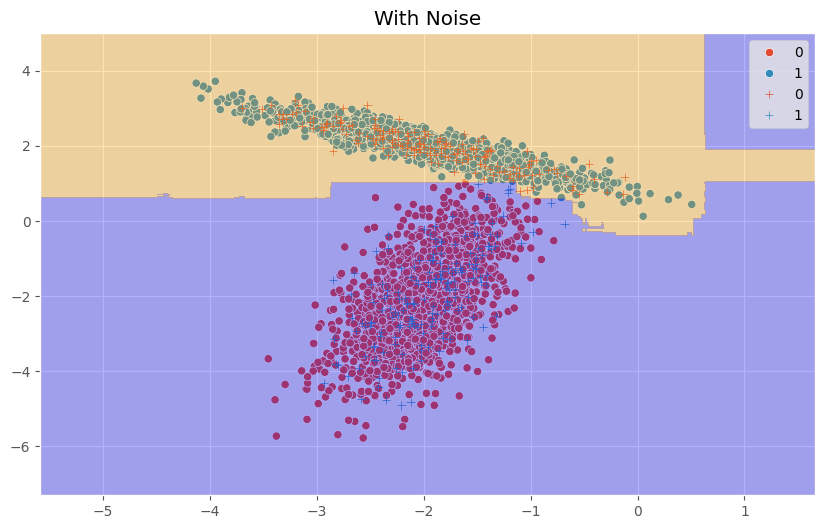

In [ ]:
clf = RandomForestClassifier(max_depth=5)

clf.fit(X_train, y_train)
y_pred = clf.predict(X_test)
score = clf.score(X_test, y_test)
print('Score=', score)
ind = y_test == y_pred
plt.subplots()
ax2 = plt.gca()

sns.scatterplot(x=X_test[ind, 0], y=X_test[ind, 1], hue=y_test[ind], ax=ax2)
sns.scatterplot(x=X_test[~ind, 0], y=X_test[~ind, 1], hue=y_test[~ind], ax=ax2, marker='+')

ax2.set_title('With Noise')

plot_step = .01
x_min, x_max = X[:, 0].min() - 1, X[:, 0].max() + 1
y_min, y_max = X[:, 1].min() - 1, X[:, 1].max() + 1

# Griiidddd
xx, yy = np.meshgrid(np.arange(x_min, x_max, plot_step), 
                         np.arange(y_min,y_max, plot_step))
    
y_pred = clf.predict(np.c_[xx.ravel(), yy.ravel()])
y_pred = y_pred.reshape(xx.shape)

cs = plt.contourf(xx, yy, y_pred, levels=1, colors=['blue', 'orange'], alpha=.3)
plt.show()

XGBoost

In [12]:
import requests

file = 'D:\\MIREA\\DPO\\Learning\\Practic1_7\\dataset.txt'
# URL = 'https://drive.google.com/uc?id=1soReu6FBB_4LxvuNnV_ULUW-WGlNaZg2'

# try:
#     response = requests.get(URL)
#     response.raise_for_status()
#     text_content = response.text

#     with open(file, 'w', encoding='utf-8') as f:
#         f.write(text_content)
    
#     print(f"Файл успешно сохранен как '{file}'")

# except requests.exceptions.RequestException as e:
#     print(f"Произошла ошибка при загрузке файла: {e}")
# except IOError as e:
#     print(f"Произошла ошибка при записи файла: {e}")

In [13]:
import xgboost
from sklearn.metrics import accuracy_score


dataset = np.loadtxt(file, delimiter=',')

X = dataset[:, 0:8]
y = dataset[:, 8]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=.33, random_state=7)

model = xgboost.XGBClassifier()
model.fit(X_train, y_train)

y_pred = model.predict(X_test)

accuracy = accuracy_score(y_test, y_pred)
print('Accuracy: %.2f%%' % (accuracy * 100.0))

Accuracy: 72.44%


Catboost — предназанчен для работы с категориальными признаками (цвет и т.д)

In [14]:
from catboost import Pool, CatBoostClassifier, cv


train_data = [['summer', 1924, 44],
              ['summer', 1932, 37],
              ['winter', 1918, 37],
              ['summer', 2012, 204]]

test_data = [['winter', 1996, 197],
              ['winter', 1968, 37],
              ['summer', 2002, 77],
              ['summer', 1948, 59]]

cat_features = [0]

train_label = ['France', 'USA', 'USA', 'UK']
test_label = ['USA', 'France', 'USA', 'UK']

train_dataset = Pool(data=train_data,
                     label=train_label,
                     cat_features=cat_features)


test_dataset = Pool(data=test_data,
                    label=test_label,
                    cat_features=cat_features)

model = CatBoostClassifier(iterations=10, 
                           learning_rate=1,
                           depth=2,
                           loss_function='MultiClass')
# iterations — кол-во моделей
model.fit(train_dataset)
y_pred = model.predict(test_dataset)
y_probs = model.predict_proba(test_dataset)
y_pred


0:	learn: 0.8393179	total: 146ms	remaining: 1.31s
1:	learn: 0.7404740	total: 147ms	remaining: 587ms
2:	learn: 0.6198197	total: 147ms	remaining: 343ms
3:	learn: 0.5414427	total: 147ms	remaining: 220ms
4:	learn: 0.4873851	total: 147ms	remaining: 147ms
5:	learn: 0.4066667	total: 147ms	remaining: 98.1ms
6:	learn: 0.3458949	total: 147ms	remaining: 63.1ms
7:	learn: 0.2989869	total: 147ms	remaining: 36.8ms
8:	learn: 0.2619887	total: 147ms	remaining: 16.4ms
9:	learn: 0.2322532	total: 148ms	remaining: 0us


array([['UK'],
       ['USA'],
       ['France'],
       ['France']], dtype=object)

Кроссвалидация

1. Делимся на группы (фолды). в том числе и данные
2. Далее меняем тестовый и тренировочный датасеты и т.д

In [15]:
cv_data = [['France', 1924, 44],
           ['USA', 1932, 37],
           ['Switzerlands', 1928, 25],
           ['Norvay', 1952, 30],
           ['Japan', 1972, 35],
           ['Mexico', 1968, 112]]

labels = [1, 1, 0, 0, 0, 1] #бинарная классификация

cat_features = [0] 

cv_dataset = Pool(data=cv_data,
                  label=labels,
                  cat_features=cat_features)

params = {'iterations': 100,
          'depth': 2,
          'loss_function': 'Logloss',
          'verbose': False}

scores = cv(cv_dataset, params,
            stratified=False,
            fold_count=3, plot=False)

Training on fold [0/3]

bestTest = 0.7062352628
bestIteration = 0

Training on fold [1/3]

bestTest = 0.3099548144
bestIteration = 99

Training on fold [2/3]

bestTest = 0.693188484
bestIteration = 0



In [16]:
scores

,iterations,test-Logloss-mean,test-Logloss-std,train-Logloss-mean,train-Logloss-std
0,0,0.701886,0.007533,0.686716,0.000000
1,1,0.702074,0.007213,0.667322,0.004916
2,2,0.699142,0.012484,0.641893,0.003615
3,3,0.709965,0.013539,0.631767,0.001427
4,4,0.716370,0.012633,0.617363,0.008033
...,...,...,...,...,...
95,95,0.886532,0.486081,0.112972,0.008340
96,96,0.888836,0.491570,0.111400,0.008220
97,97,0.890328,0.496243,0.109881,0.008180
98,98,0.892651,0.501611,0.108247,0.007978


P-tuning гиперпараметров

In [17]:
from sklearn.datasets._base import get_data_home
print(get_data_home())

C:\Users\nuyki\scikit_learn_data


In [ ]:
from catboost import CatBoostRegressor
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.inspection import permutation_importance
from sklearn.datasets import fetch_california_housing
from sklearn.datasets import fetch_openml

df = fetch_openml(name="California_Housing", as_frame=False, version=7)
X, y = df.data, df.target

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=.2, random_state=5)
train_dataset = Pool(X_train, y_train)
test_dataset = Pool(X_test, y_test)

In [ ]:
model = CatBoostRegressor(loss_function='RMSE')

In [23]:
# сетка параметров
grid = {'iterations': [100, 150, 200],
        'learning_rate': [0.03, .1],
        'depth': [2, 4, 6, 8],
        'l2_leaf_reg': [.2, .5, 1, 3]}

model.grid_search(grid, train_dataset)
# Естетственно, не надо переусердствовать, много моделей, очень

0:	learn: 230044.2195995	test: 231276.5583132	best: 231276.5583132 (0)	total: 2.02ms	remaining: 200ms
1:	learn: 224280.7743729	test: 225481.8996862	best: 225481.8996862 (1)	total: 3.35ms	remaining: 164ms
2:	learn: 218766.3746449	test: 219941.5353350	best: 219941.5353350 (2)	total: 4.64ms	remaining: 150ms
3:	learn: 213519.7443906	test: 214698.9055985	best: 214698.9055985 (3)	total: 5.87ms	remaining: 141ms
4:	learn: 208311.1324855	test: 209458.2424193	best: 209458.2424193 (4)	total: 7.08ms	remaining: 135ms
5:	learn: 203350.8403725	test: 204450.8737484	best: 204450.8737484 (5)	total: 8.34ms	remaining: 131ms
6:	learn: 198589.2163700	test: 199632.5926574	best: 199632.5926574 (6)	total: 9.59ms	remaining: 127ms
7:	learn: 193988.6232128	test: 194987.6820587	best: 194987.6820587 (7)	total: 10.8ms	remaining: 124ms
8:	learn: 189358.1144002	test: 190377.5891482	best: 190377.5891482 (8)	total: 12.1ms	remaining: 123ms
9:	learn: 185083.4943575	test: 186066.3918627	best: 186066.3918627 (9)	total: 13.4

{'params': {'depth': 8,
  'learning_rate': 0.1,
  'l2_leaf_reg': 0.2,
  'iterations': 200},
 'cv_results': defaultdict(list,
             {'iterations': [0,
               1,
               2,
               3,
               4,
               5,
               6,
               7,
               8,
               9,
               10,
               11,
               12,
               13,
               14,
               15,
               16,
               17,
               18,
               19,
               20,
               21,
               22,
               23,
               24,
               25,
               26,
               27,
               28,
               29,
               30,
               31,
               32,
               33,
               34,
               35,
               36,
               37,
               38,
               39,
               40,
               41,
               42,
               43,
               44,
               4

In [24]:
y_pred = model.predict(X_test)
print('Testing performance')
print('PMSE: {:.2f}'.format(np.sqrt(mean_squared_error(y_test, y_pred))))
print('R2: {:.2f}'.format(r2_score(y_test, y_pred)))

Testing performance
PMSE: 47738.00
R2: 0.83


<Axes: >

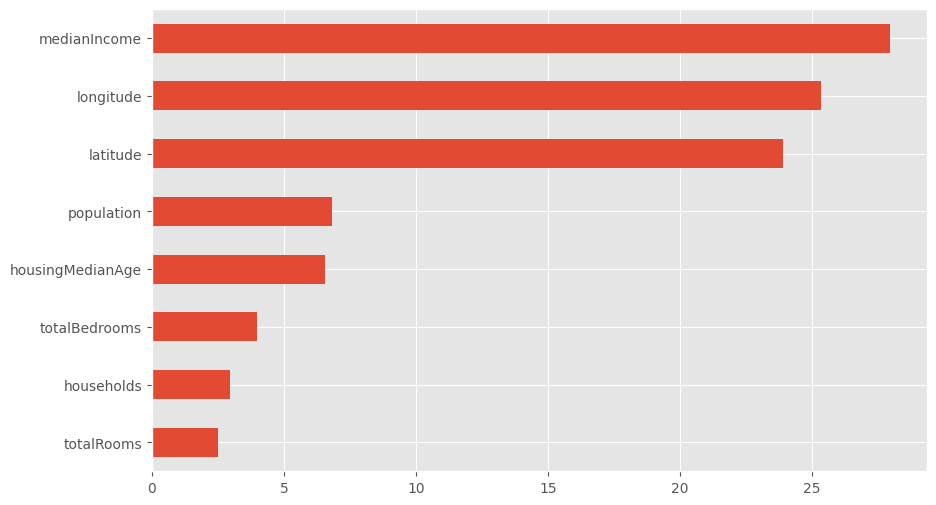

In [26]:
sorted_feature_importance = model.feature_importances_.argsort()
(pd.Series(model.feature_importances_, index=df.feature_names).sort_values().plot(kind='barh'))

In [28]:
from sklearn.linear_model import Ridge


model_ridge = Ridge()
model_ridge.fit(X_train, y_train)
model_ridge_train = model_ridge.predict(X_train)
model_ridge_test = model_ridge.predict(X_test)

train_dataset = Pool(X_train, y_train, baseline=model_ridge_train)
test_dataset = Pool(X_test, y_test, baseline=model_ridge_test)

model = CatBoostRegressor(loss_function='RMSE')
model.fit(train_dataset, eval_set=test_dataset)
y_pred = model.predict(test_dataset)

print('Testing performance')
print('PMSE: {:.2f}'.format(np.sqrt(mean_squared_error(y_test, y_pred))))
print('R2: {:.2f}'.format(r2_score(y_test, y_pred)))

Learning rate set to 0.07828
0:	learn: 69022.6511046	test: 69661.1291175	best: 69661.1291175 (0)	total: 2.6ms	remaining: 2.6s
1:	learn: 68459.1344624	test: 69075.7419006	best: 69075.7419006 (1)	total: 5.11ms	remaining: 2.55s
2:	learn: 67985.1410557	test: 68580.8483925	best: 68580.8483925 (2)	total: 7.88ms	remaining: 2.62s
3:	learn: 67593.8037300	test: 68161.1067627	best: 68161.1067627 (3)	total: 10.1ms	remaining: 2.51s
4:	learn: 67336.8090590	test: 67845.9938059	best: 67845.9938059 (4)	total: 12.4ms	remaining: 2.48s
5:	learn: 67026.6847373	test: 67512.7781351	best: 67512.7781351 (5)	total: 14.6ms	remaining: 2.42s
6:	learn: 66621.1449159	test: 67133.8442101	best: 67133.8442101 (6)	total: 16.7ms	remaining: 2.37s
7:	learn: 66247.2968674	test: 66771.2769573	best: 66771.2769573 (7)	total: 19.4ms	remaining: 2.41s
8:	learn: 65928.1449686	test: 66460.9299569	best: 66460.9299569 (8)	total: 21.7ms	remaining: 2.39s
9:	learn: 65718.0302951	test: 66245.9498366	best: 66245.9498366 (9)	total: 23.9ms	

1. Найти ещё датасеты на кегле
2. скалёрн пайплайн изучить
3. Трансформация данных
4. Градиентные бустинги
5. y - джибиэн